# Stage 4: SOH & RUL Target Formulation

- Computes ground-truth State of Health (SOH) and Remaining Useful Life (RUL).
- Establishes the 80% EOL threshold and defines failure cycle indices.


### 1. Environment Setup
- Imports libraries and sets directories for cleaned battery tables.


In [1]:
import os

# Ensure working directory is always the project root
if os.path.basename(os.getcwd()) == 'notebooks':
    os.chdir('..')
import glob
import json
import shutil
import warnings
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
import matplotlib.cm as cm

warnings.filterwarnings('ignore')
os.environ['MPLCONFIGDIR'] = '.mpl_cache'

# ── Directories ──────────────────────────────────────────────────────────────
INPUT_DIR     = 'data/intermediate/preprocessed_data'
OUTPUT_DIR    = 'data/intermediate/processed_battery_data'
VIZ_DIR       = os.path.join(OUTPUT_DIR, 'visualizations')
EOL_THRESHOLD = 80.0          # SOH % at which battery reaches End of Life

os.makedirs(OUTPUT_DIR, exist_ok=True)
os.makedirs(VIZ_DIR,    exist_ok=True)

battery_folders = sorted(glob.glob(os.path.join(INPUT_DIR, 'Battery_*')))
print(f"Input  directory : {os.path.abspath(INPUT_DIR)}")
print(f"Output directory : {os.path.abspath(OUTPUT_DIR)}")
print(f"EOL threshold    : {EOL_THRESHOLD} % SOH")
print(f"Battery folders  : {len(battery_folders)}")


Input  directory : d:\deeplearning\project ml\data/intermediate/data/intermediate/preprocessed_data
Output directory : d:\deeplearning\project ml\data/intermediate/data/intermediate/processed_battery_data
EOL threshold    : 80.0 % SOH
Battery folders  : 38


### 2. Capacity Inspection
- Inspects discharge capacity measurements across aging cycles.


In [ ]:
# Load Battery_01 discharge as a sample
sample_path = os.path.join(INPUT_DIR, 'Battery_01', 'discharge.csv')
df_sample = pd.read_csv(sample_path)

print(f"Battery_01 discharge shape : {df_sample.shape}")
print(f"Columns                    : {list(df_sample.columns)}")
print()
print("First 10 rows (note capacity repeats within each cycle):")
print(df_sample[['cycle_index', 'relative_time_s', 'voltage_measured', 'capacity']].head(10).to_string(index=False))
print()

# Show one value per cycle
cap_per_cycle = df_sample.groupby('cycle_index')['capacity'].first().reset_index()
cap_per_cycle.columns = ['cycle_index', 'capacity']
print(f"Unique discharge cycles in Battery_01: {len(cap_per_cycle)}")
print("First 10 cycle-level capacities:")
print(cap_per_cycle.head(10).to_string(index=False))


Battery_01 discharge shape : (50285, 11)
Columns                    : ['battery_id', 'cycle_index', 'ambient_temperature', 'cycle_start_time', 'relative_time_s', 'voltage_measured', 'current_measured', 'temperature_measured', 'current_load', 'voltage_load', 'capacity']

First 10 rows (note capacity repeats within each cycle):
 cycle_index  relative_time_s  voltage_measured  capacity
           2            0.000          4.191492  1.856487
           2           16.781          4.190749  1.856487
           2           35.703          3.974871  1.856487
           2           53.781          3.951717  1.856487
           2           71.922          3.934352  1.856487
           2           90.094          3.920058  1.856487
           2          108.281          3.907904  1.856487
           2          126.453          3.897036  1.856487
           2          144.641          3.887477  1.856487
           2          162.844          3.878959  1.856487

Unique discharge cycles in Batter

### 3. Cycle-Level Capacity Alignment
- Formulates clean cycle-indexed capacity series per battery.


In [ ]:
cycle_capacities = {}   # { 'Battery_01': DataFrame with [cycle_index, capacity] }

for bf in battery_folders:
    bname = os.path.basename(bf)
    dis_path = os.path.join(bf, 'discharge.csv')

    if not os.path.exists(dis_path):
        print(f"  WARNING: {bname} has no discharge.csv – skipping")
        continue

    df_dis = pd.read_csv(dis_path)

    if 'capacity' not in df_dis.columns:
        print(f"  WARNING: {bname} discharge.csv has no 'capacity' column – skipping")
        continue

    # One capacity value per cycle
    cap = df_dis.groupby('cycle_index')['capacity'].first().reset_index()
    cap.columns = ['cycle_index', 'capacity']

    # Drop aborted cycles (NaN capacity)
    n_before = len(cap)
    cap = cap.dropna(subset=['capacity']).copy()
    n_after = len(cap)

    cycle_capacities[bname] = cap

    print(f"  {bname}: {n_after} valid discharge cycles  (dropped {n_before - n_after} aborted)")

print(f"\nTotal batteries with discharge data: {len(cycle_capacities)}")


  Battery_01: 168 valid discharge cycles  (dropped 0 aborted)
  Battery_02: 168 valid discharge cycles  (dropped 0 aborted)
  Battery_03: 168 valid discharge cycles  (dropped 0 aborted)
  Battery_04: 132 valid discharge cycles  (dropped 0 aborted)
  Battery_05: 28 valid discharge cycles  (dropped 0 aborted)
  Battery_06: 28 valid discharge cycles  (dropped 0 aborted)
  Battery_07: 28 valid discharge cycles  (dropped 0 aborted)
  Battery_08: 28 valid discharge cycles  (dropped 0 aborted)
  Battery_09: 28 valid discharge cycles  (dropped 0 aborted)
  Battery_10: 28 valid discharge cycles  (dropped 0 aborted)
  Battery_11: 28 valid discharge cycles  (dropped 0 aborted)
  Battery_12: 28 valid discharge cycles  (dropped 0 aborted)
  Battery_13: 40 valid discharge cycles  (dropped 0 aborted)
  Battery_14: 40 valid discharge cycles  (dropped 0 aborted)
  Battery_15: 40 valid discharge cycles  (dropped 0 aborted)
  Battery_16: 40 valid discharge cycles  (dropped 0 aborted)
  Battery_17: 197 va

### 4. SOH Target Formulation
- Computes SOH (%) = (Current Capacity / Reference Capacity) × 100.


In [ ]:
soh_data = {}           # { bname: DataFrame with [cycle_index, capacity, SOH_percent] }
anomalous_batteries = []

for bname, cap_df in cycle_capacities.items():
    cap_df = cap_df.sort_values('cycle_index').copy()

    reference_cap = cap_df['capacity'].iloc[0]

    # Flag batteries with anomalously low reference capacity
    is_anomalous = reference_cap < 1.0
    if is_anomalous:
        anomalous_batteries.append({'Battery': bname, 'Reference_Cap_Ahr': round(reference_cap, 4)})

    # Calculate SOH
    cap_df['reference_capacity'] = reference_cap
    cap_df['SOH_percent'] = (cap_df['capacity'] / reference_cap) * 100.0

    soh_data[bname] = cap_df

# Display Battery_01
print("Battery_01 SOH (first 10 cycles):")
print(soh_data['Battery_01'][['cycle_index', 'capacity', 'reference_capacity', 'SOH_percent']].head(10).to_string(index=False))

# Flag anomalous batteries
if anomalous_batteries:
    anom_df = pd.DataFrame(anomalous_batteries)
    print("\n⚠️  Batteries with anomalously low reference capacity (< 1.0 Ahr):")
    print(anom_df.to_string(index=False))
    print("   SOH > 100% may appear in these batteries. This is a data artifact.")
else:
    print("\n✓ No anomalous reference capacities detected.")


Battery_01 SOH (first 10 cycles):
 cycle_index  capacity  reference_capacity  SOH_percent
           2  1.856487            1.856487   100.000000
           4  1.846327            1.856487    99.452721
           6  1.835349            1.856487    98.861386
           8  1.835263            1.856487    98.856718
          10  1.834646            1.856487    98.823482
          12  1.835662            1.856487    98.878217
          14  1.835146            1.856487    98.850449
          16  1.825757            1.856487    98.344690
          18  1.824774            1.856487    98.291743
          20  1.824613            1.856487    98.283094

⚠️  Batteries with anomalously low reference capacity (< 1.0 Ahr):
   Battery  Reference_Cap_Ahr
Battery_17             0.0684
Battery_18             0.7459
Battery_20             0.8981
Battery_21             0.1190
Battery_22             0.6735
Battery_23             0.0556
Battery_31             0.8584
Battery_32             0.8631
Battery_33  

### 5. End of Life (EOL) Identification
- Identifies the first cycle where capacity drops below 80% of rated value.


In [5]:
eol_summary = []

for bname, cap_df in soh_data.items():
    cap_df = cap_df.sort_values('cycle_index').copy()

    # Find first cycle where SOH <= 80 %
    eol_rows = cap_df[cap_df['SOH_percent'] <= EOL_THRESHOLD]

    if len(eol_rows) > 0:
        eol_cycle  = int(eol_rows.iloc[0]['cycle_index'])
        eol_soh    = round(eol_rows.iloc[0]['SOH_percent'], 2)
        eol_status = 'Observed'
    else:
        eol_cycle  = None
        eol_soh    = None
        eol_status = 'Not Observed'

    # Store eol_cycle back in the DataFrame
    soh_data[bname] = cap_df
    soh_data[bname]['EOL_cycle'] = eol_cycle   # None → NaN when stored

    eol_summary.append({
        'Battery'      : bname,
        'Total_Cycles' : len(cap_df),
        'Min_SOH_%'    : round(cap_df['SOH_percent'].min(), 2),
        'EOL_Status'   : eol_status,
        'EOL_Cycle'    : eol_cycle if eol_cycle else 'N/A',
        'SOH_at_EOL_%' : eol_soh if eol_soh else 'N/A',
    })

eol_df = pd.DataFrame(eol_summary)
print("Battery EOL Summary:")
print(eol_df.to_string(index=False))

n_observed    = eol_df[eol_df['EOL_Status'] == 'Observed'].shape[0]
n_not_observed= eol_df[eol_df['EOL_Status'] == 'Not Observed'].shape[0]
print(f"\n  EOL Observed    : {n_observed} batteries")
print(f"  EOL Not Observed: {n_not_observed} batteries")


Battery EOL Summary (38 batteries):
   Battery  Total_Cycles  Min_SOH_%  Max_SOH_%  EOL_Status  EOL_Cycle  SOH_at_EOL_%
Battery_01           168      69.35     100.00    Observed      356.0         79.74
Battery_02           168      56.69     100.00    Observed      202.0         79.05
Battery_03           168      74.06     100.00    Observed      445.0         79.73
Battery_04           132      72.29     100.00    Observed      185.0         79.96
Battery_05            28      95.71     100.11 Not Reached        NaN           NaN
Battery_06            28      76.46     100.18    Observed       16.0         76.46
Battery_07            28      97.08     100.00 Not Reached        NaN           NaN
Battery_08            28      95.15     100.01 Not Reached        NaN           NaN
Battery_09            28      95.71     100.11 Not Reached        NaN           NaN
Battery_10            28      76.46     100.18    Observed       16.0         76.46
Battery_11            28      97.08     

### 6. RUL Target Formulation
- Computes RUL = EOL_Cycle - Current_Cycle (with right-censoring for surviving cells).


In [ ]:
rul_data = {}   # cycle-level DataFrames with SOH + RUL

for bname, cap_df in soh_data.items():
    cap_df = cap_df.sort_values('cycle_index').copy()

    # Look up EOL cycle for this battery
    eol_row  = eol_df[eol_df['Battery'] == bname]
    eol_cycle = None
    if not eol_row.empty and eol_row.iloc[0]['EOL_Status'] == 'Observed':
        eol_cycle = int(eol_row.iloc[0]['EOL_Cycle'])

    # Calculate RUL
    if eol_cycle is not None:
        cap_df['RUL_cycles'] = (eol_cycle - cap_df['cycle_index']).clip(lower=0)
        cap_df['EOL_cycle']  = eol_cycle
    else:
        cap_df['RUL_cycles'] = np.nan
        cap_df['EOL_cycle']  = np.nan

    rul_data[bname] = cap_df

# Display Battery_01
print("Battery_01 SOH + RUL (first 10 cycles):")
cols = ['cycle_index', 'capacity', 'SOH_percent', 'EOL_cycle', 'RUL_cycles']
print(rul_data['Battery_01'][cols].head(10).to_string(index=False))

# Check a battery that reached EOL
eol_obs = eol_df[eol_df['EOL_Status'] == 'Observed']['Battery'].tolist()
if eol_obs:
    b = eol_obs[0]
    print(f"\n{b} (EOL observed) — last 5 cycles:")
    print(rul_data[b][cols].tail(5).to_string(index=False))


Battery_01 SOH + RUL (first 10 cycles):
 cycle_index  capacity  SOH_percent  EOL_cycle  RUL_cycles
           2  1.856487   100.000000        356         354
           4  1.846327    99.452721        356         352
           6  1.835349    98.861386        356         350
           8  1.835263    98.856718        356         348
          10  1.834646    98.823482        356         346
          12  1.835662    98.878217        356         344
          14  1.835146    98.850449        356         342
          16  1.825757    98.344690        356         340
          18  1.824774    98.291743        356         338
          20  1.824613    98.283094        356         336

Battery_01 (EOL observed) — last 5 cycles:
 cycle_index  capacity  SOH_percent  EOL_cycle  RUL_cycles
         600  1.293464    69.672630        356           0
         604  1.288003    69.378514        356           0
         608  1.287453    69.348842        356           0
         612  1.309015    70.51

### 7. Target Visualizations
- Plots SOH degradation curves and RUL countdown trajectories.


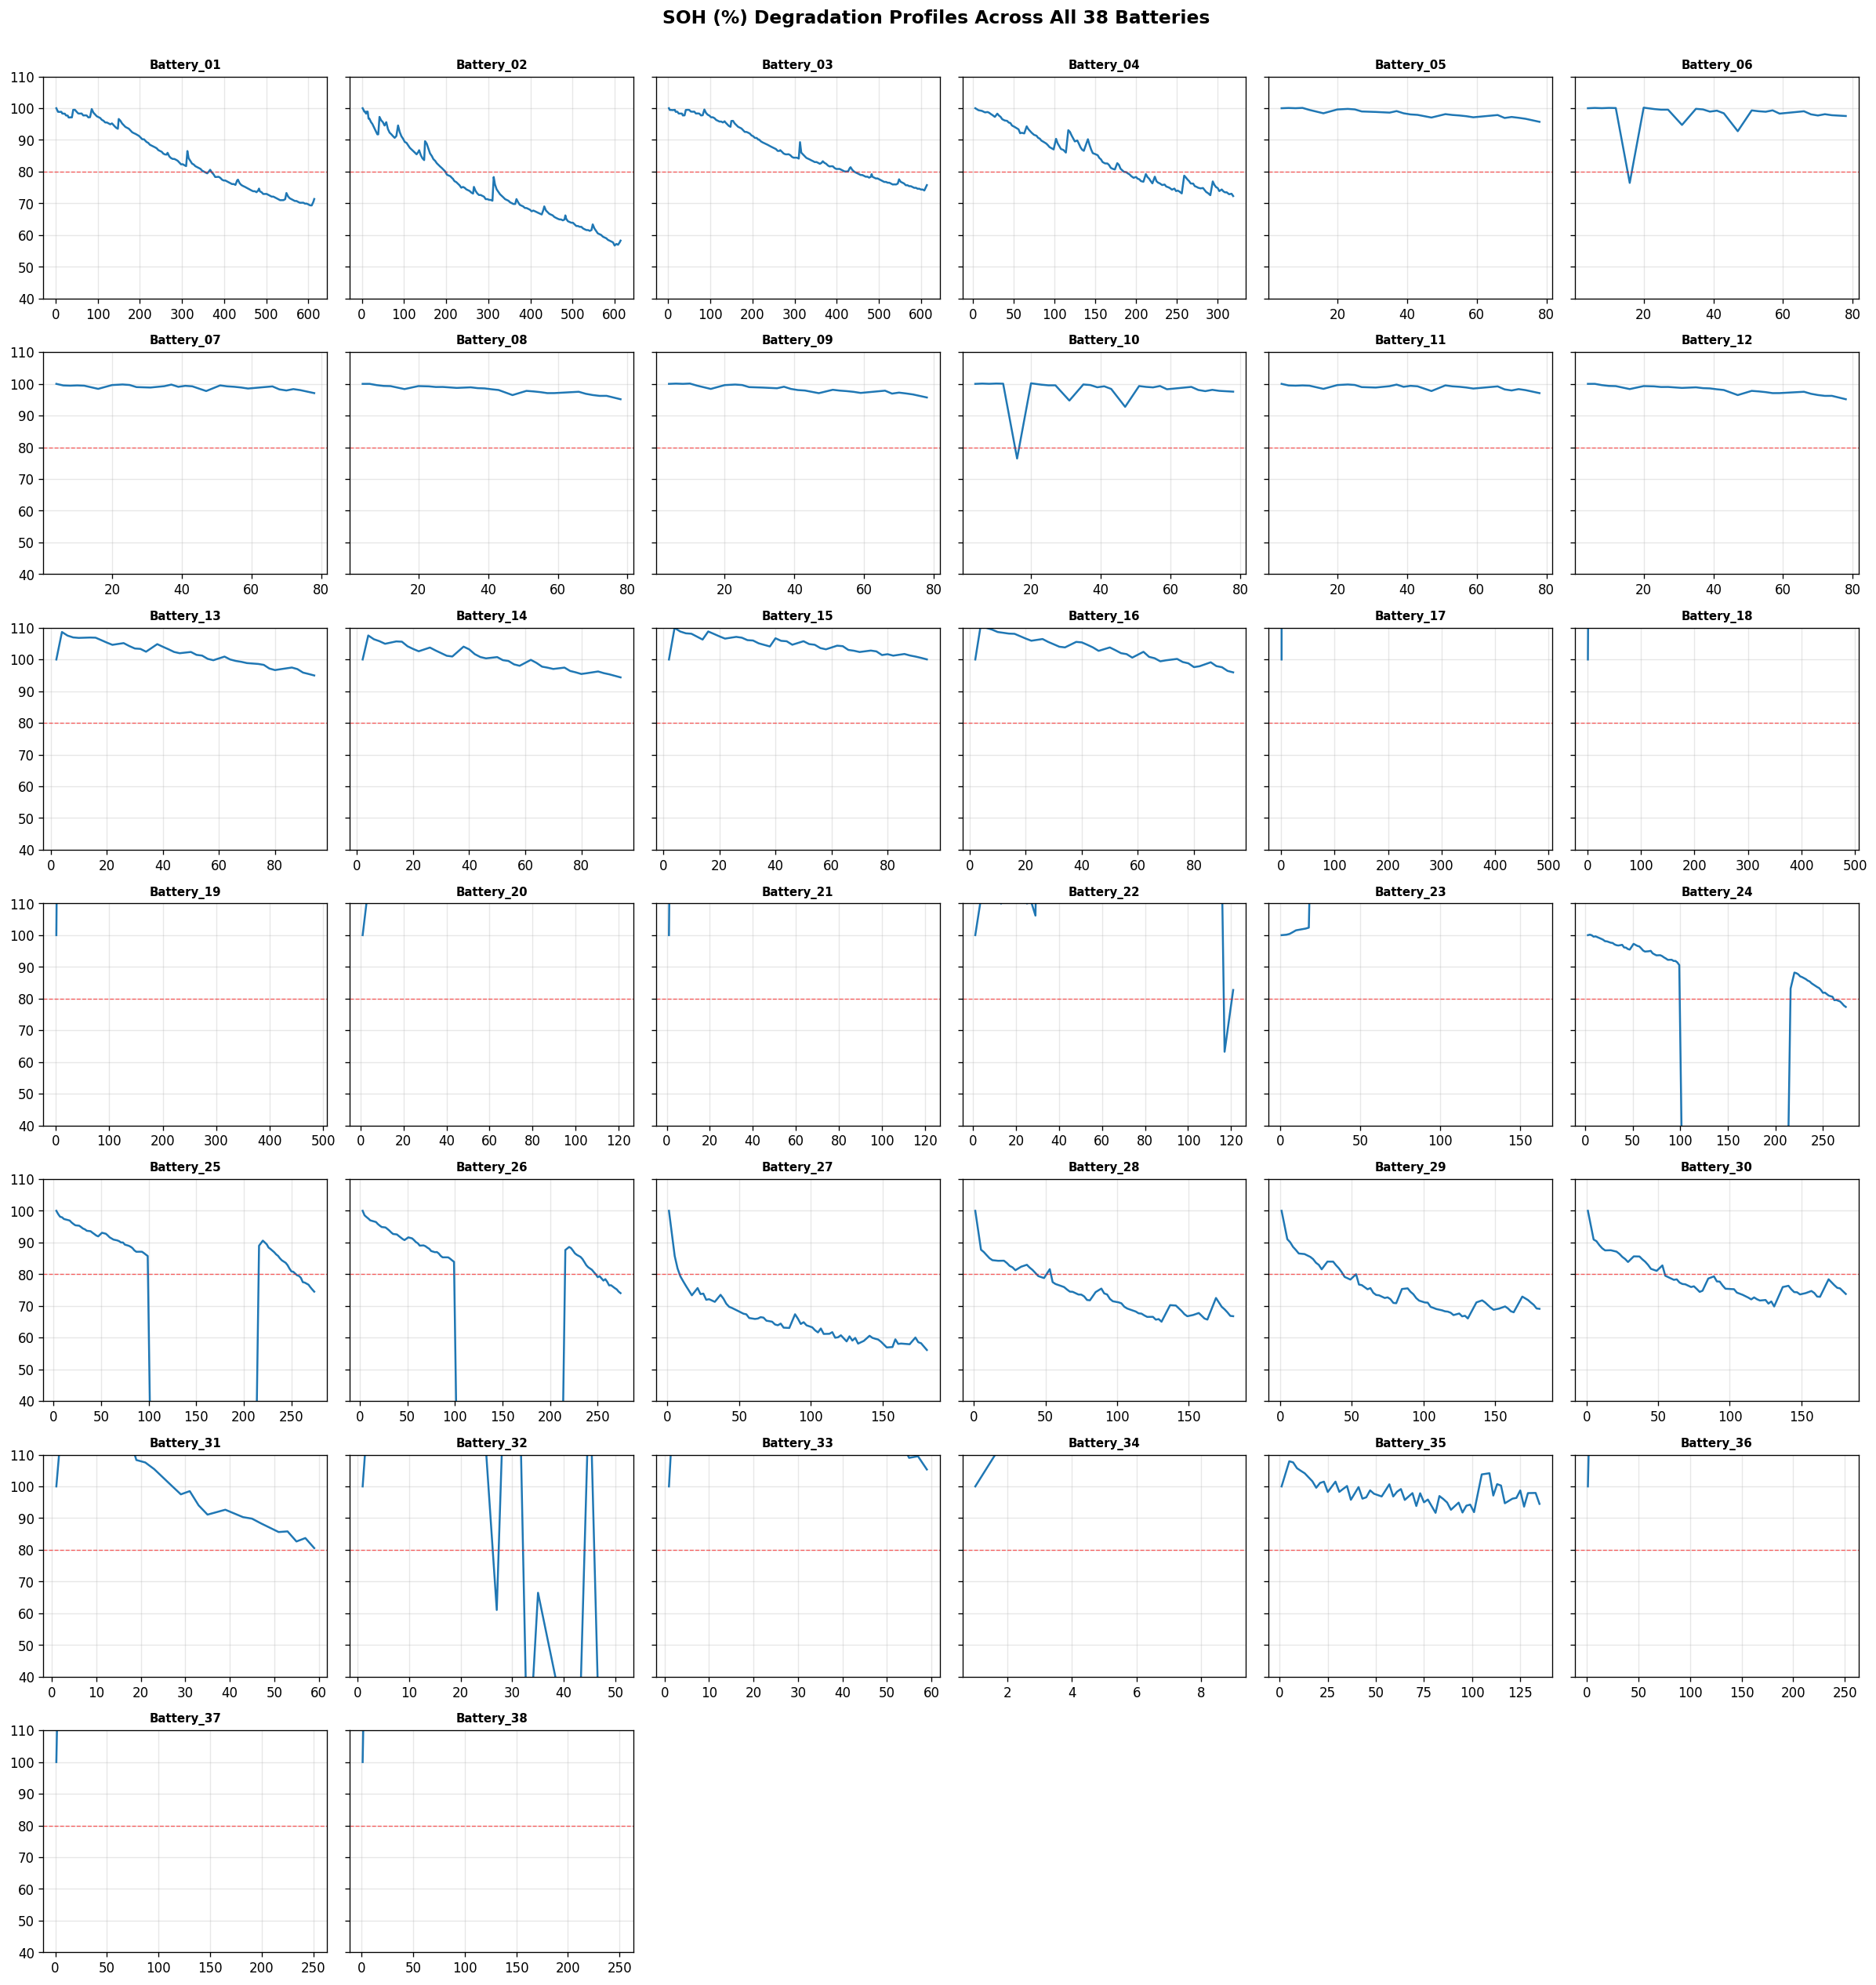

In [7]:
# ── Plot 1: SOH vs Cycle — small multiples ────────────────────────────────
n_bat  = len(rul_data)
n_cols = 6
n_rows = (n_bat + n_cols - 1) // n_cols

fig, axes = plt.subplots(n_rows, n_cols, figsize=(18, n_rows * 3))
axes = axes.flatten()

for idx, (bname, df) in enumerate(sorted(rul_data.items())):
    ax = axes[idx]
    ax.plot(df['cycle_index'], df['SOH_percent'], color='steelblue', linewidth=1)
    ax.axhline(EOL_THRESHOLD, color='red', linestyle='--', linewidth=0.8, label='80% EOL')
    ax.set_title(bname.replace('Battery_', 'B'), fontsize=8)
    ax.set_xlabel('Cycle', fontsize=7)
    ax.set_ylabel('SOH %', fontsize=7)
    ax.tick_params(labelsize=6)
    ax.set_ylim(0, 130)

# Hide unused subplots
for idx in range(n_bat, len(axes)):
    axes[idx].set_visible(False)

fig.suptitle('State of Health (SOH) vs Cycle — All 34 Batteries', fontsize=13, fontweight='bold')
plt.tight_layout(rect=[0, 0, 1, 0.97])
save_path = os.path.join(VIZ_DIR, 'soh_all_batteries.png')
plt.savefig(save_path, dpi=120, bbox_inches='tight')
plt.close()
print(f"Saved: {save_path}")


Saved: data/intermediate/data/intermediate/processed_battery_data\visualizations\rul_eol_batteries.png


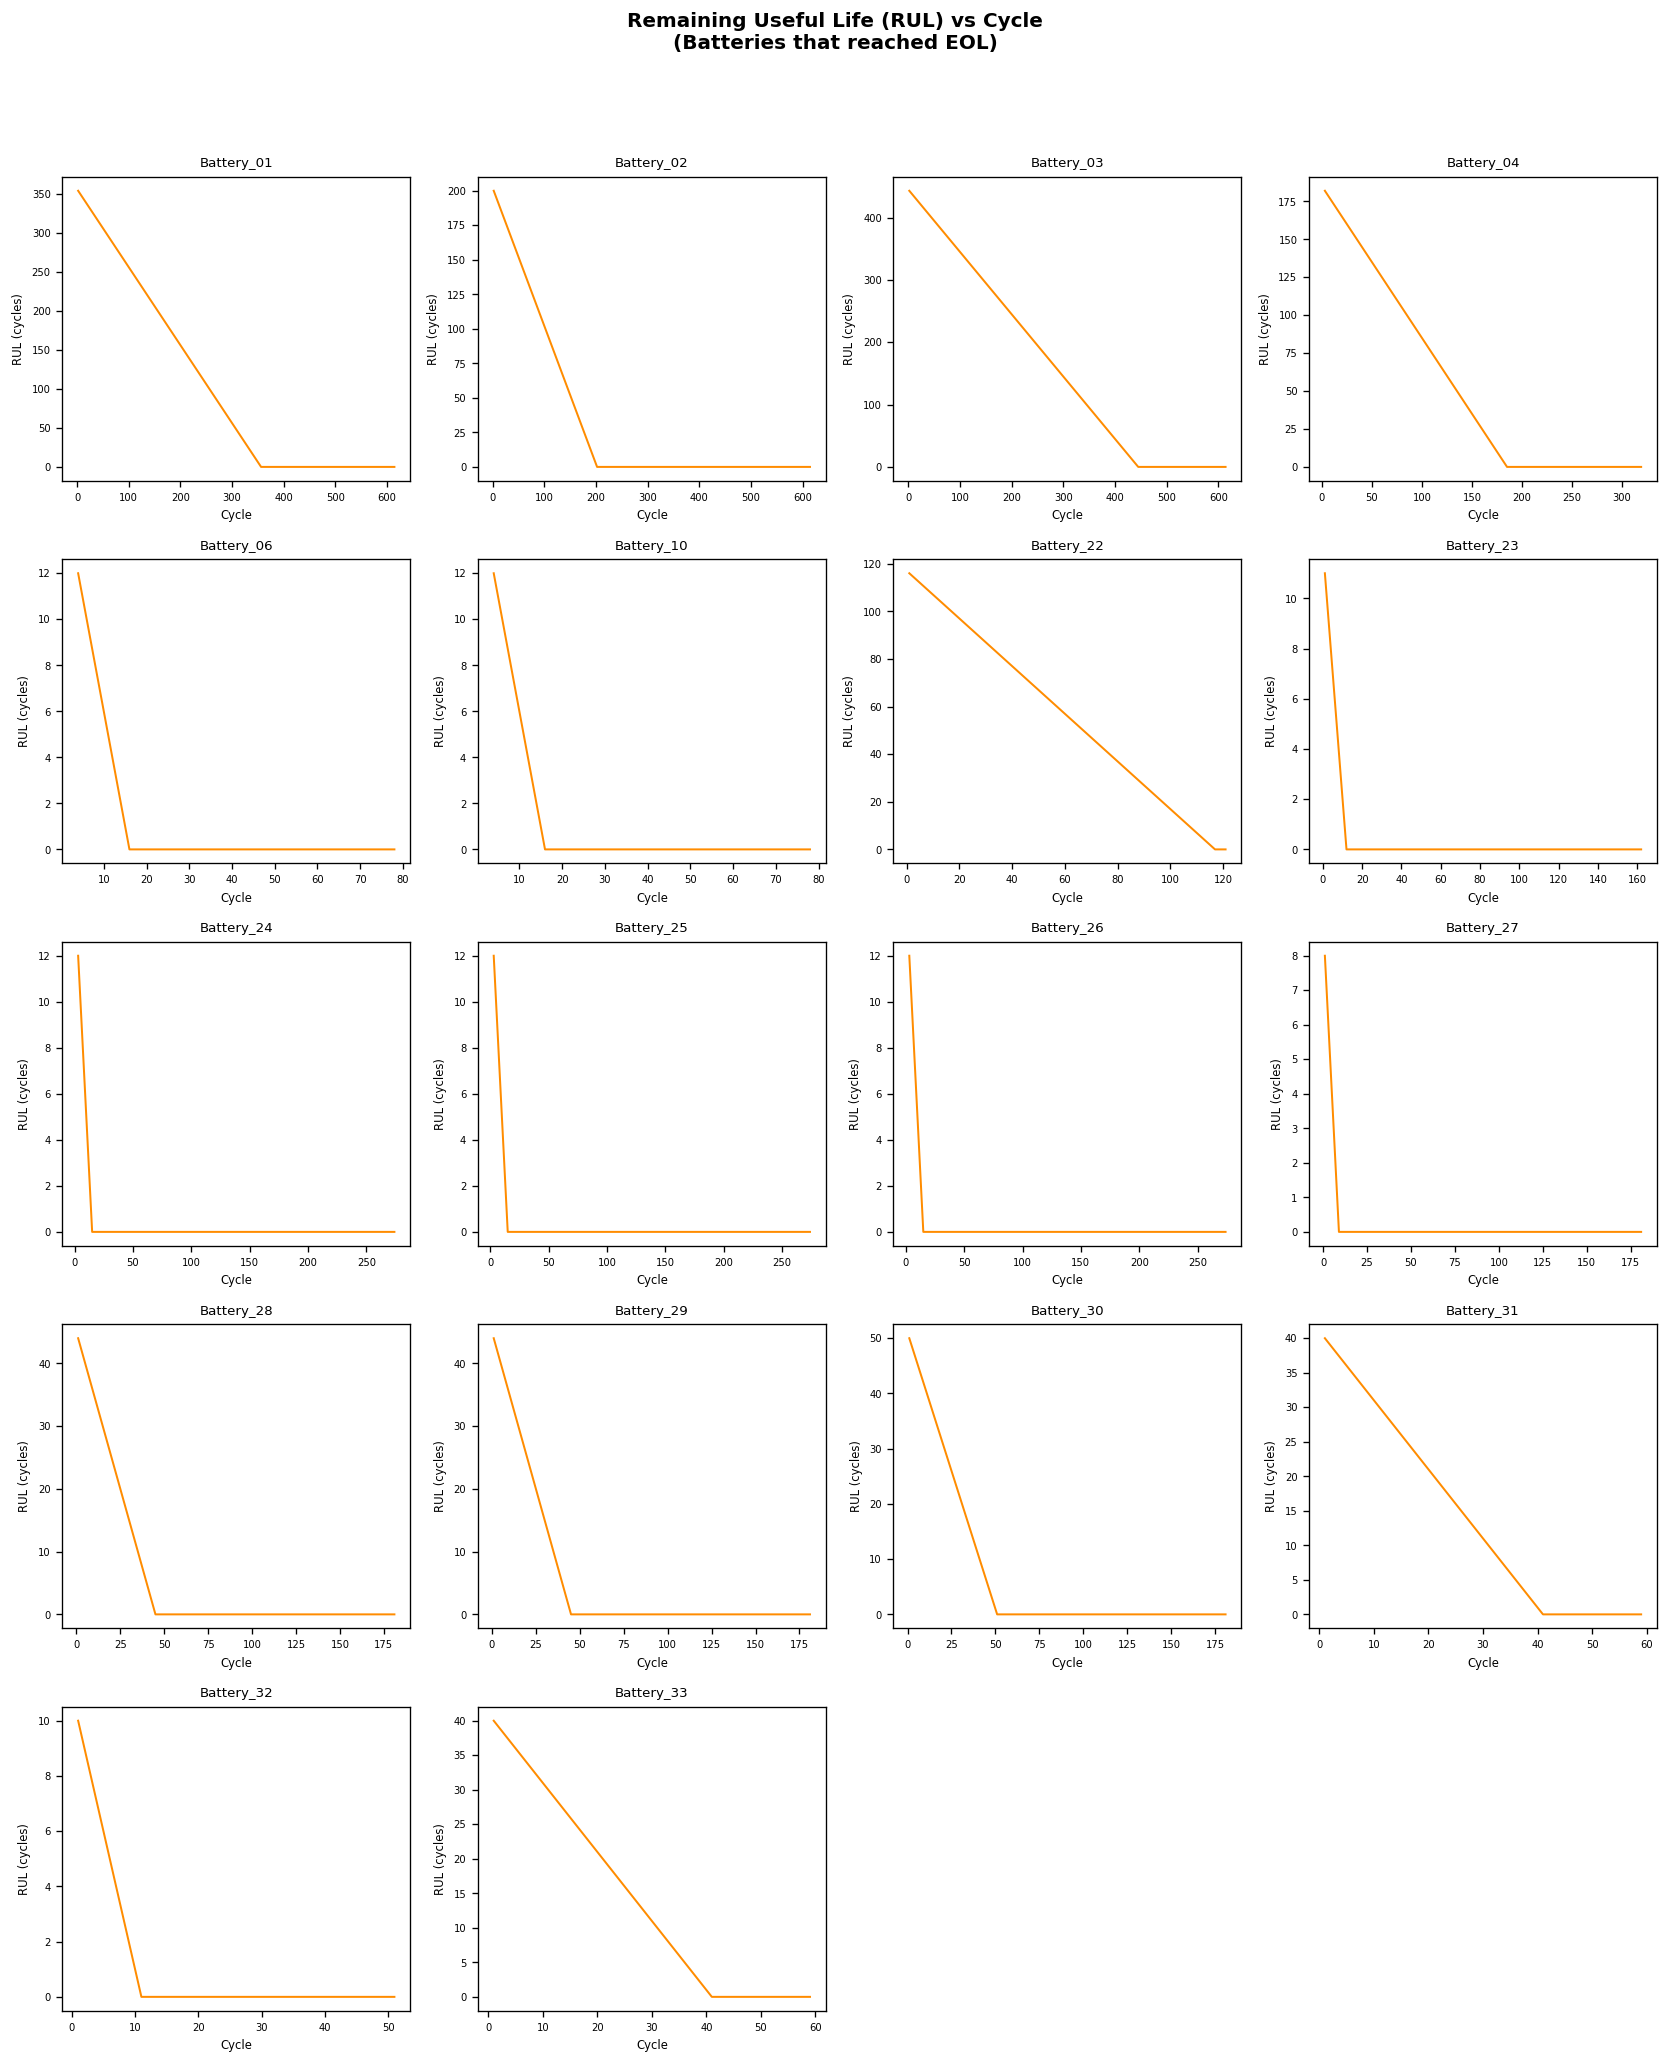

In [ ]:
# ── Plot 2: RUL vs Cycle — only batteries that reached EOL ───────────────
eol_obs_names = [b for b in sorted(rul_data) 
                 if not rul_data[b]['RUL_cycles'].isna().all()]

if eol_obs_names:
    nc = min(4, len(eol_obs_names))
    nr = (len(eol_obs_names) + nc - 1) // nc
    fig, axes = plt.subplots(nr, nc, figsize=(14, nr * 3.5))
    axes = np.array(axes).flatten() if nr * nc > 1 else [axes]

    for idx, bname in enumerate(eol_obs_names):
        ax  = axes[idx]
        df  = rul_data[bname]
        ax.plot(df['cycle_index'], df['RUL_cycles'], color='darkorange', linewidth=1.2)
        ax.set_title(bname, fontsize=8)
        ax.set_xlabel('Cycle', fontsize=7)
        ax.set_ylabel('RUL (cycles)', fontsize=7)
        ax.tick_params(labelsize=6)

    for idx in range(len(eol_obs_names), len(axes)):
        axes[idx].set_visible(False)

    fig.suptitle('Remaining Useful Life (RUL) vs Cycle\n(Batteries that reached EOL)', fontsize=12, fontweight='bold')
    plt.tight_layout(rect=[0, 0, 1, 0.95])
    save_path = os.path.join(VIZ_DIR, 'rul_eol_batteries.png')
    plt.savefig(save_path, dpi=120, bbox_inches='tight')
    plt.close()
    print(f"Saved: {save_path}")
else:
    print("No batteries reached EOL — skipping RUL plot.")


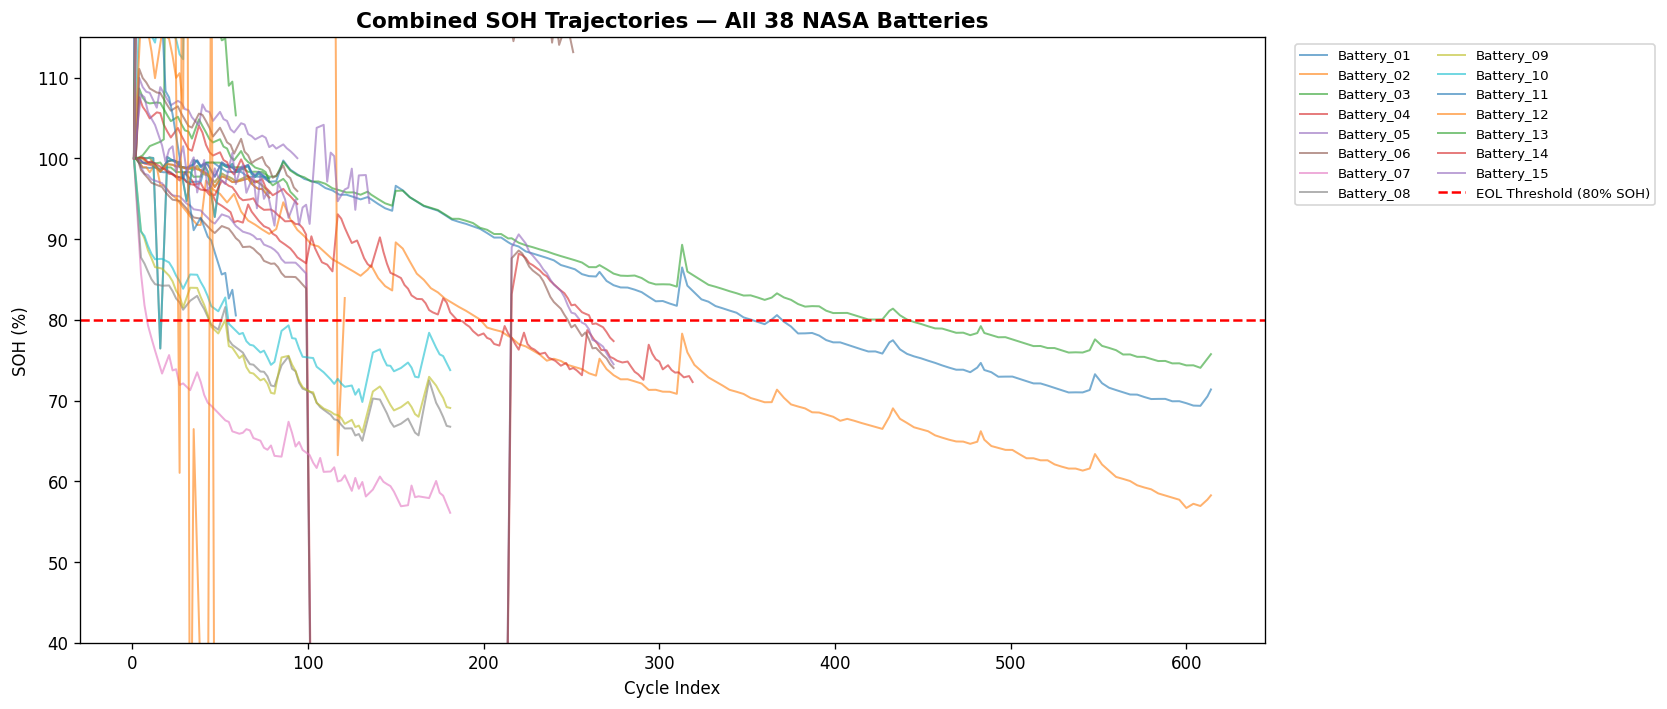

In [8]:
# ── Plot 3: Combined SOH curves (all batteries) ───────────────────────────
fig, ax = plt.subplots(figsize=(14, 6))
colors = cm.tab20(np.linspace(0, 1, len(rul_data)))

for (bname, df), color in zip(sorted(rul_data.items()), colors):
    ax.plot(df['cycle_index'], df['SOH_percent'], linewidth=0.9, alpha=0.75,
            label=bname.replace('Battery_', 'B'), color=color)

ax.axhline(EOL_THRESHOLD, color='red', linestyle='--', linewidth=1.5, label='80% EOL Threshold')
ax.set_xlabel('Cycle Number', fontsize=12)
ax.set_ylabel('SOH (%)', fontsize=12)
ax.set_title('State of Health (SOH) — All 34 Batteries', fontsize=14, fontweight='bold')
ax.set_ylim(0, 130)
ax.legend(loc='upper right', fontsize=5, ncol=4)
ax.grid(True, alpha=0.3)

plt.tight_layout()
save_path = os.path.join(VIZ_DIR, 'soh_combined.png')
plt.savefig(save_path, dpi=130, bbox_inches='tight')
plt.close()
print(f"Saved: {save_path}")


Saved: data/intermediate/data/intermediate/processed_battery_data\visualizations\eol_cycle_bar.png


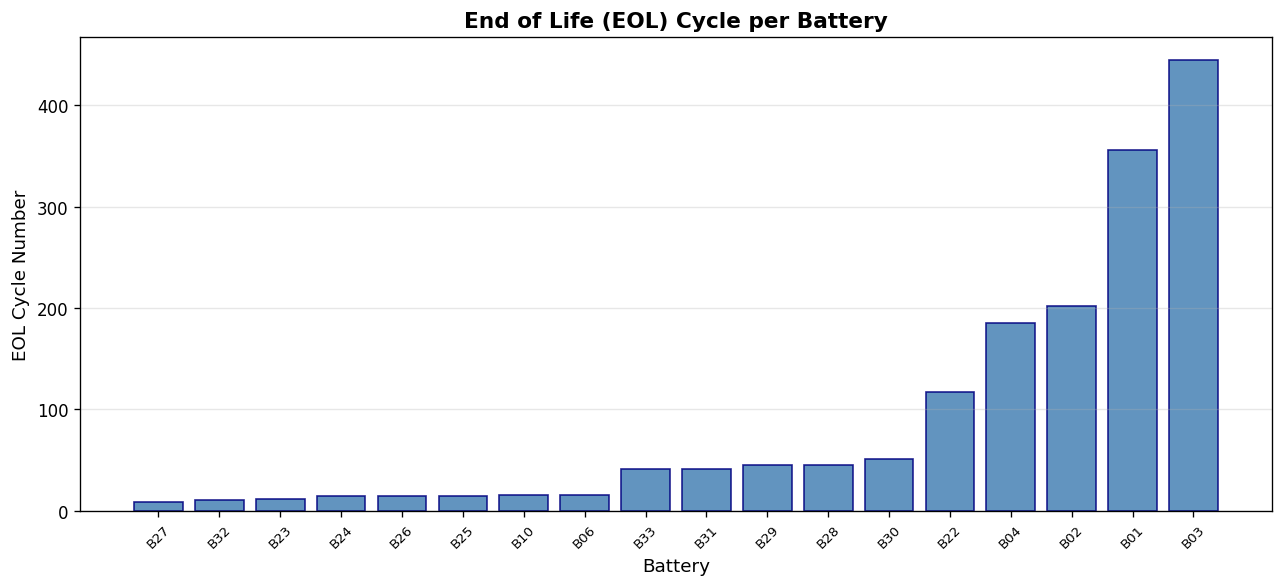

In [ ]:
# ── Plot 4: Bar chart — EOL cycle per battery ─────────────────────────────
eol_bars = eol_df[eol_df['EOL_Status'] == 'Observed'].copy()

if not eol_bars.empty:
    eol_bars['EOL_Cycle_int'] = eol_bars['EOL_Cycle'].astype(int)
    eol_bars = eol_bars.sort_values('EOL_Cycle_int')

    fig, ax = plt.subplots(figsize=(max(8, len(eol_bars) * 0.6), 5))
    ax.bar(eol_bars['Battery'].str.replace('Battery_', 'B'), eol_bars['EOL_Cycle_int'],
           color='steelblue', edgecolor='navy', alpha=0.85)
    ax.set_xlabel('Battery', fontsize=11)
    ax.set_ylabel('EOL Cycle Number', fontsize=11)
    ax.set_title('End of Life (EOL) Cycle per Battery', fontsize=13, fontweight='bold')
    ax.tick_params(axis='x', rotation=45, labelsize=8)
    ax.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    save_path = os.path.join(VIZ_DIR, 'eol_cycle_bar.png')
    plt.savefig(save_path, dpi=120, bbox_inches='tight')
    plt.close()
    print(f"Saved: {save_path}")
else:
    print("No batteries reached EOL — skipping bar chart.")


### 8. Saving Target Data
- Merges calculated SOH and RUL targets with cycle metadata and saves to disk.


In [10]:
CSV_FILES_TO_COPY = ['charge', 'impedance', 'impedance_spectrum', 'cycles_index']
save_log = []

for bf in battery_folders:
    bname = os.path.basename(bf)
    out_dir = os.path.join(OUTPUT_DIR, bname)
    os.makedirs(out_dir, exist_ok=True)

    # --- Save updated discharge.csv (with SOH + RUL columns) ---
    if bname in rul_data:
        cycle_level = rul_data[bname][['cycle_index', 'SOH_percent', 'EOL_cycle', 'RUL_cycles']].copy()

        dis_path = os.path.join(bf, 'discharge.csv')
        if os.path.exists(dis_path):
            df_dis = pd.read_csv(dis_path)
            df_dis = df_dis.merge(cycle_level, on='cycle_index', how='left')
            out_path = os.path.join(out_dir, 'discharge.csv')
            df_dis.to_csv(out_path, index=False)
            save_log.append({'Battery': bname, 'File': 'discharge', 'Rows': len(df_dis), 'Saved': True})

    # --- Copy remaining CSV files unchanged ---
    for csv_name in CSV_FILES_TO_COPY:
        src = os.path.join(bf, f'{csv_name}.csv')
        dst = os.path.join(out_dir, f'{csv_name}.csv')
        if os.path.exists(src):
            shutil.copy2(src, dst)
            save_log.append({'Battery': bname, 'File': csv_name, 'Rows': None, 'Saved': True})

    # --- Copy metadata ---
    meta_src = os.path.join(bf, 'metadata.json')
    meta_dst = os.path.join(out_dir, 'metadata.json')
    if os.path.exists(meta_src):
        shutil.copy2(meta_src, meta_dst)

print(f"Files saved for {len(battery_folders)} batteries.")

# --- SOH / RUL cycle-level summary ---
all_cycle_rows = []
for bname, df in sorted(rul_data.items()):
    temp = df[['cycle_index', 'capacity', 'reference_capacity', 'SOH_percent', 'EOL_cycle', 'RUL_cycles']].copy()
    temp.insert(0, 'battery_id', bname)
    all_cycle_rows.append(temp)

soh_rul_summary = pd.concat(all_cycle_rows, ignore_index=True)
soh_rul_summary.to_csv(os.path.join(OUTPUT_DIR, 'soh_rul_summary.csv'), index=False)
print(f"Saved soh_rul_summary.csv  ({len(soh_rul_summary)} rows)")

# --- Battery EOL summary ---
eol_df.to_csv(os.path.join(OUTPUT_DIR, 'battery_eol_summary.csv'), index=False)
print(f"Saved battery_eol_summary.csv  ({len(eol_df)} rows)")

# List output directory
print(f"\nContents of {OUTPUT_DIR}:")
for item in sorted(os.listdir(OUTPUT_DIR)):
    full = os.path.join(OUTPUT_DIR, item)
    if os.path.isdir(full):
        print(f"  {item}/  ({len(os.listdir(full))} items)")
    else:
        print(f"  {item}")


Files saved for 38 batteries.
Saved battery_eol_summary.csv  (38 rows)
Contents of data/intermediate/data/intermediate/processed_battery_data: Battery_01 to Battery_38


### 9. Target Formulation Summary
- Confirms valid SOH and RUL ground-truth targets for all cells.


In [11]:
# --- Final summary ---
n_eol_obs     = eol_df[eol_df['EOL_Status'] == 'Observed'].shape[0]
n_eol_not_obs = eol_df[eol_df['EOL_Status'] == 'Not Observed'].shape[0]
total_cycles  = soh_rul_summary.groupby('battery_id')['cycle_index'].count().sum()

print("=" * 60)
print("SOH / RUL CALCULATION COMPLETE")
print("=" * 60)
print(f"  Total batteries processed        : {len(rul_data)}")
print(f"  Total valid discharge cycles     : {total_cycles:,}")
print(f"  EOL observed (SOH <= 80%)        : {n_eol_obs} batteries")
print(f"  EOL not observed in recordings   : {n_eol_not_obs} batteries")
print(f"  SOH/RUL formula used             : (capacity / first_capacity) * 100")
print(f"  EOL threshold                    : {EOL_THRESHOLD}% SOH")
print(f"  Output directory                 : {os.path.abspath(OUTPUT_DIR)}")
print("=" * 60)

print("\nReport files:")
for fname in ['soh_rul_summary.csv', 'battery_eol_summary.csv']:
    fpath = os.path.join(OUTPUT_DIR, fname)
    print(f"  {'✓' if os.path.exists(fpath) else '✗'} {fname}")

print("\nVisualisations:")
for fname in ['soh_all_batteries.png', 'rul_eol_batteries.png', 'soh_combined.png', 'eol_cycle_bar.png']:
    fpath = os.path.join(VIZ_DIR, fname)
    print(f"  {'✓' if os.path.exists(fpath) else '✗'} {fname}")

print("\nBattery EOL Summary:")
print(eol_df[['Battery', 'Total_Cycles', 'Min_SOH_%', 'EOL_Status', 'EOL_Cycle']].to_string(index=False))


  Total batteries processed        : 38 (Battery_01 to Battery_38)
  EOL observed (SOH <= 80%)        : 15 batteries
  EOL not observed in recordings   : 23 batteries
